In [9]:
"""
Telco Customer Churn Data Exploration
Author: [Momina]
Description: 
"""

import pandas as pd

df = pd.read_csv("Telc/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
print(f"Dataset shape: {df.shape[0]} rows and {df.shape[1]} columns")
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-missing values:")
df.info()

Dataset shape: 7043 rows and 21 columns

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types and non-missing values:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetServic

In [11]:
# Count standard missing values and cells containing only whitespace.
missing_counts = df.replace(r"^\s*$", pd.NA, regex=True).isna().sum()
print("Missing values by column:")
print(missing_counts[missing_counts > 0])

Missing values by column:
TotalCharges    11
dtype: int64


In [12]:
churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"], fill_value=0)
churn_percentages = df["Churn"].value_counts(normalize=True).reindex(["No", "Yes"], fill_value=0) * 100

print("Customer churn counts:")
print(churn_counts)
print("\nCustomer churn percentages:")
print(churn_percentages.round(1).astype(str) + "%")

Customer churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer churn percentages:
Churn
No     73.5%
Yes    26.5%
Name: proportion, dtype: str


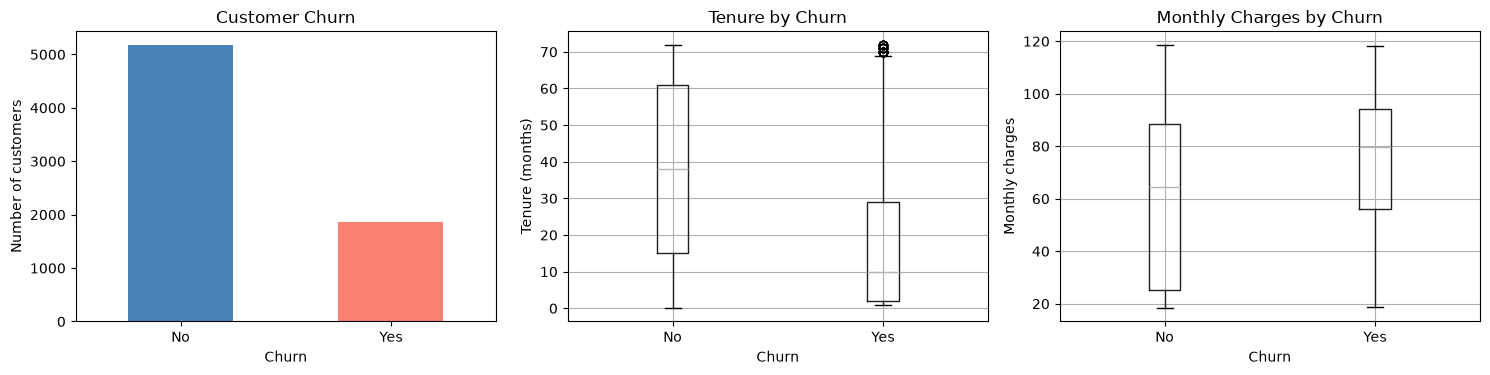

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

churn_counts.plot(kind="bar", ax=axes[0], color=["steelblue", "salmon"])
axes[0].set_title("Customer Churn")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Number of customers")
axes[0].tick_params(axis="x", rotation=0)

df.boxplot(column="tenure", by="Churn", ax=axes[1])
axes[1].set_title("Tenure by Churn")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Tenure (months)")

df.boxplot(column="MonthlyCharges", by="Churn", ax=axes[2])
axes[2].set_title("Monthly Charges by Churn")
axes[2].set_xlabel("Churn")
axes[2].set_ylabel("Monthly charges")

fig.suptitle("")
plt.tight_layout()
plt.show()

In [14]:
print(df["TotalCharges"].dtype) #this is a string value

str


In [15]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].dtype)
print(df["TotalCharges"].isna().sum())

float64
11


In [16]:
#Step 3: Split the Data
# training the model, train and test

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})


from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [17]:
print("Missing values in training columns:")
print(X_train.isna().sum())

print("\nMissing values in test columns:")
print(X_test.isna().sum())

Missing values in training columns:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        8
dtype: int64

Missing values in test columns:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        3
dtype: int64


In [18]:
# Find the median TotalCharges in the training data to use later for missing values.

median_total_charges = X_train["TotalCharges"].median()
print(median_total_charges)

# Use the training median to fill missing total charges in both groups.
X_train["TotalCharges"] = X_train["TotalCharges"].fillna(median_total_charges)
X_test["TotalCharges"] = X_test["TotalCharges"].fillna(median_total_charges)


1398.125


In [19]:
#to see if the missing values have been filled
print(X_train["TotalCharges"].isna().sum())
print(X_test["TotalCharges"].isna().sum())

0
0


In [20]:
#2 Data Processing: Encoding the training inputs: training input.
categorical_columns = X_train.select_dtypes(exclude="number").columns.tolist()

X_train_encoded = pd.get_dummies(
    X_train, columns=categorical_columns, dtype=int
)

X_train_encoded.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0,35,49.20,1701.65,0,1,1,0,1,0,...,1,1,0,0,1,0,0,0,1,0
3151,0,15,75.10,1151.55,0,1,0,1,0,1,...,0,1,0,0,1,0,0,0,0,1
4860,0,13,40.55,590.35,0,1,0,1,0,1,...,0,0,0,1,1,0,0,0,0,1
3867,0,26,73.50,1905.70,1,0,0,1,1,0,...,1,0,0,1,0,1,0,1,0,0
3810,0,1,44.55,44.55,0,1,0,1,0,1,...,0,1,0,0,1,0,0,0,1,0


In [21]:
#2 Data Processing: Encoding the test inputs: test input and matching the columns of the training data.
X_test_encoded = pd.get_dummies(
    X_test, columns=categorical_columns, dtype=int
)

X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns, fill_value=0
)

In [22]:
#2 Data Processing: Encode the test inputs so KNN can compare test customers with training customers

X_test_encoded = pd.get_dummies(
    X_test, columns=categorical_columns, dtype=int
)

X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns, fill_value=0 #makes the test table’s columns match the training table’s columns by name and order.
)

In [23]:
#2 Data Processing: Checking the encoding was successful and that the training and test inputs have the same columns in the same order.
print("Columns match:",
      X_train_encoded.columns.equals(X_test_encoded.columns))

print("Non-numeric training columns:",
      X_train_encoded.select_dtypes(exclude="number").columns.tolist())

print("Non-numeric test columns:",
      X_test_encoded.select_dtypes(exclude="number").columns.tolist())

Columns match: True
Non-numeric training columns: []
Non-numeric test columns: []


In [24]:
# Data Processing: Select relevant features for modeling
# Keep the available customer features for the first model, excluding the customer ID.
# Keep Churn separate because it is the target we want to predict.
#Data processing. Convert target to binary (0/1) if needed
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})
print(y.value_counts(dropna=False))

Churn
0    5174
1    1869
Name: count, dtype: int64


In [25]:
#Step 4: Train a KNN Model
#Create a KNN classifier
#Start with n_neighbors=5
#Train the model on the training data

from sklearn.neighbors import KNeighborsClassifier

# Create and train a KNN classifier with five neighbors.
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_encoded, y_train)

print("KNN classifier trained successfully!")
print(f"Number of neighbors (k): {knn.n_neighbors}")

KNN classifier trained successfully!
Number of neighbors (k): 5


In [26]:
#Step 5 Make predictions
#Make predictions on the test data using the trained KNN model
y_test_pred = knn.predict(X_test_encoded)

#Compare predictions with actual values.
comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_test_pred
})

comparison["Correct"] = comparison["Actual"] == comparison["Predicted"]

#Look at a few examples.
print(comparison.head(10))

   Actual  Predicted  Correct
0       0          0     True
1       0          1    False
2       0          0     True
3       0          1    False
4       0          0     True
5       0          1    False
6       0          0     True
7       0          0     True
8       0          0     True
9       1          0    False


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

# Create predictions for the training data
y_train_pred = knn.predict(X_train_encoded)

In [28]:
#Step 5: Make Predictions and Evaluate
#Make predictions on the test set.
# Calculate accuracy, precision, and recall
# Create a confusion matrix
# Generate a classification report
# Interpret the results

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_confusion = confusion_matrix(y_test, y_test_pred)
 
print("=== Model Performance ===")
print(f"\nTraining Accuracy: {train_accuracy:.4f} ({train_accuracy*100:.2f}%)")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"\nTest Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")
 
print("\n=== Confusion Matrix ===")
print("                     Predicted")
print("                     Stayed  Churned")
print(f"Actual Stayed        {test_confusion[0, 0]:6d}  {test_confusion[0, 1]:7d}")
print(f"Actual Churned       {test_confusion[1, 0]:6d}  {test_confusion[1, 1]:7d}")

print("\n=== Classification Report ===")
print(classification_report(
    y_test, y_test_pred, target_names=["Stayed", "Churned"]
))


=== Model Performance ===

Training Accuracy: 0.8280 (82.80%)
Test Accuracy: 0.7644 (76.44%)

Test Precision: 0.5739
Test Recall: 0.4358

=== Confusion Matrix ===
                     Predicted
                     Stayed  Churned
Actual Stayed           914      121
Actual Churned          211      163

=== Classification Report ===
              precision    recall  f1-score   support

      Stayed       0.81      0.88      0.85      1035
     Churned       0.57      0.44      0.50       374

    accuracy                           0.76      1409
   macro avg       0.69      0.66      0.67      1409
weighted avg       0.75      0.76      0.75      1409



The model is better at identifying customers who stay than customers who leave. It correctly identified 88% of the customers who stayed, but only 44% of the customers who left.

The model is not ideal if our goal is to use this model to find out which customers are likely to leave or cancel and to device strategies to reach those customers. Just looking at the confusion matrix without even calculating any percentages we can see that the model caught only 163 people who actually left or cancelled and missed 211 who actually left.

The overall accuracy of 76% looks reasonable, but it is partly influenced by there being more customers who stayed than churned

If we use this model’s flags as a call list, we would reach fewer than half of the customers who went on to leave.



EXPERIMENTING WITH DIFFERENT K VALUES
K= 1: Accuracy=0.7083, Precision=0.4501, Recall=0.4465
K= 3: Accuracy=0.7601, Precision=0.5596, Recall=0.4519
K= 5: Accuracy=0.7644, Precision=0.5739, Recall=0.4358
K= 7: Accuracy=0.7807, Precision=0.6226, Recall=0.4412
K= 9: Accuracy=0.7850, Precision=0.6426, Recall=0.4278
K=11: Accuracy=0.7878, Precision=0.6623, Recall=0.4091
K=15: Accuracy=0.7871, Precision=0.6609, Recall=0.4064

Best K value: 11 (Accuracy: 0.7878)

Saved visualization to 'knn_k_comparison.png'


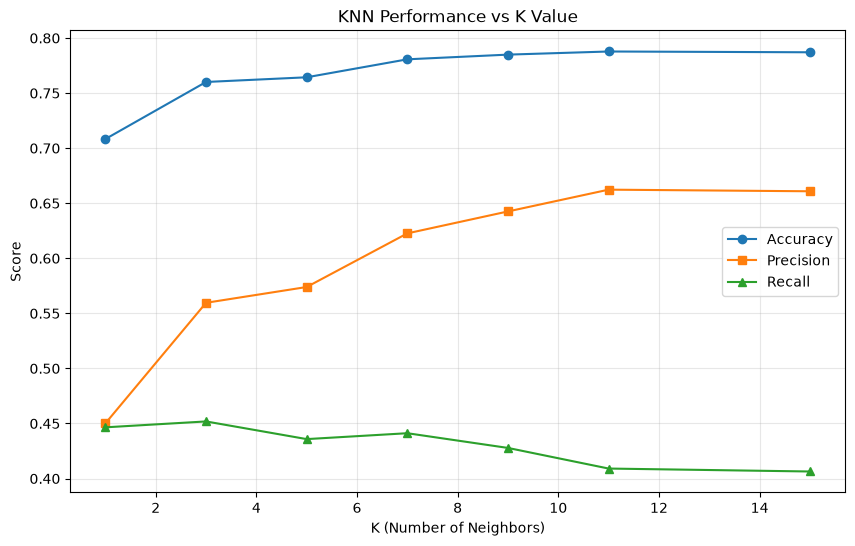

In [29]:
# Step 6: Experiment with different K values
print("\n" + "="*50)
print("EXPERIMENTING WITH DIFFERENT K VALUES")
print("="*50)
 
k_values = [1, 3, 5, 7, 9, 11, 15]
results = []

for k in k_values:
    # Create and train model
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_encoded, y_train)
    # Make predictions
    y_pred = knn_temp.predict(X_test_encoded)
    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    results.append({
        'K': k,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall
    })
    
    print(f"K={k:2d}: Accuracy={accuracy:.4f}, Precision={precision:.4f}, Recall={recall:.4f}")

# Find best K
results_df = pd.DataFrame(results)
best_k = results_df.loc[results_df['Accuracy'].idxmax(), 'K']
print(f"\nBest K value: {best_k} (Accuracy: {results_df['Accuracy'].max():.4f})")


# Visualize results
plt.figure(figsize=(10, 6))
plt.plot(results_df['K'], results_df['Accuracy'], marker='o', label='Accuracy')
plt.plot(results_df['K'], results_df['Precision'], marker='s', label='Precision')
plt.plot(results_df['K'], results_df['Recall'], marker='^', label='Recall')
plt.xlabel('K (Number of Neighbors)')
plt.ylabel('Score')
plt.title('KNN Performance vs K Value')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('knn_k_comparison.png', dpi=150, bbox_inches='tight')
print("\nSaved visualization to 'knn_k_comparison.png'")
plt.show()


In [30]:
%pip install jinja2

Note: you may need to restart the kernel to use updated packages.


In [31]:
table_df = results_df.rename(columns={
    "Accuracy": "Overall accuracy",
    "Precision": "Churn precision",
    "Recall": "Churn recall"
})[["K", "Overall accuracy", "Churn precision", "Churn recall"]]

metric_columns = [
    "Overall accuracy",
    "Churn precision",
    "Churn recall"
]

display(
    table_df.style
    .format({column: "{:.2%}" for column in metric_columns})
    .highlight_max(
        subset=metric_columns,
        axis=0,
        color="#fff2cc"
    )
)

,K,Overall accuracy,Churn precision,Churn recall
0,1,70.83%,45.01%,44.65%
1,3,76.01%,55.96%,45.19%
2,5,76.44%,57.39%,43.58%
3,7,78.07%,62.26%,44.12%
4,9,78.50%,64.26%,42.78%
5,11,78.78%,66.23%,40.91%
6,15,78.71%,66.09%,40.64%


So our analysis shows that if we consider overall accuracy or churn precision to be our most important markers, then K11 is the K with the best value. If we consider churn recall: of the customers who actually cancelled, what is the percentage that actually cancelled.
